In [3]:
import os
from pathlib import Path
import torch
from torchvision.transforms import ToTensor, Resize, Compose

import numpy as np
import pandas as pd
import pickle
from tqdm import tqdm
import ot

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
import torch.nn.functional as F

import timm
import tifffile

import scanpy
import novae

import matplotlib.pyplot as plt

from utils import get_null_distribution, PCA_plot 

In [4]:
# tissue_type = "lung_cancer"
# data_dir = "/nfs/team361/dj16/data/Xenium_Prime_Human_Lung_Cancer_FFPE/"
# image_file = Path(data_dir, "Xenium_Prime_Human_Lung_Cancer_FFPE_he_image.ome.tif")

# tissue_type = "breast_cancer"
# data_dir = "/nfs/team361/dj16/data/Xenium_Prime_Breast_Cancer_FFPE/"
# image_file = Path(data_dir, "Xenium_Prime_Breast_Cancer_FFPE_he_image.ome.tif")

# tissue_type = "ovarian_cancer"
# data_dir = "/nfs/team361/dj16/data/Xenium_Prime_Ovarian_Cancer_FFPE_XRrun/"
# image_file = Path(data_dir, "Xenium_Prime_Ovarian_Cancer_FFPE_XRrun_he_image.ome.tif")

tissue_type = "lymph_node"
data_dir = "/nfs/team361/dj16/data/Xenium_Prime_Human_Lymph_Node_Reactive_FFPE/"
image_file = Path(data_dir, "Xenium_Prime_Human_Lymph_Node_Reactive_FFPE_he_image.ome.tif")

# ====================================================================
## Should be preprocessed by data_preprocessing.ipynb
spatial_file = Path(data_dir, f"spatial_preprocessed_{tissue_type}.h5")

# Get pretrained model

In [5]:
# novae embeddings are already computed by data_preprocessing.ipynb
x1 = scanpy.read_h5ad(spatial_file)

In [9]:
# Image encoder
image_data = tifffile.imread(image_file)

In [ ]:
pretrained_ckpt_dir = "../assets/ckpts/vit_large_patch16_224.dinov2.uni_mass100k/"

os.listdir("../assets/ckpts/vit_large_patch16_224.dinov2.uni_mass100k/")

os.makedirs(pretrained_ckpt_dir, exist_ok=True)

image_encoder = timm.create_model(
    "vit_large_patch16_224",
    img_size=224,
    patch_size=16,
    init_values=1e-5,
    num_classes=0,
    dynamic_img_size=True,
)
image_encoder.load_state_dict(
    torch.load(
        os.path.join(pretrained_ckpt_dir, "pytorch_model.bin"), map_location="cpu"
    ),
    strict=True,
)
image_encoder.eval()

# Sinlge FOV embedding

In [29]:
image_data.shape

(30987, 28915, 3)

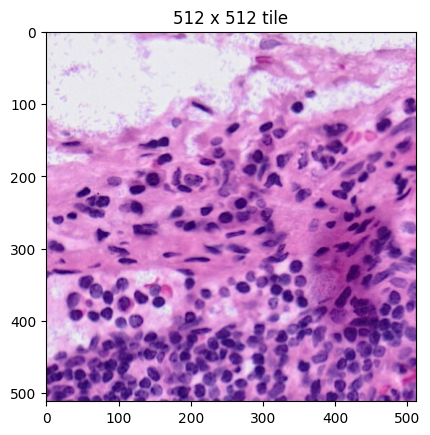

In [87]:
fov_size = 512

x_start, y_start = 2000, 15000

transform = Compose([
    ToTensor(), 
    Resize((224, 224)) # → Resize for ViT input
])

plt.imshow(image_data[x_start:x_start+fov_size,y_start:y_start+fov_size,:])
plt.title(f"{fov_size} x {fov_size} tile")
plt.show()

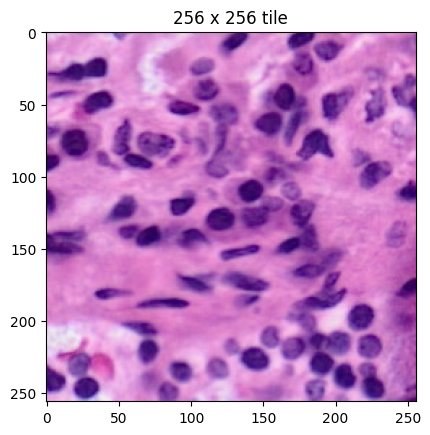

In [88]:
fov_size = 256

x_start, y_start = 2000+fov_size//2, 15000+fov_size//2

transform = Compose([
    ToTensor(), 
    Resize((224, 224)) # → Resize for ViT input
])

plt.imshow(image_data[x_start:x_start+fov_size,y_start:y_start+fov_size,:])
plt.title(f"{fov_size} x {fov_size} tile")
plt.show()

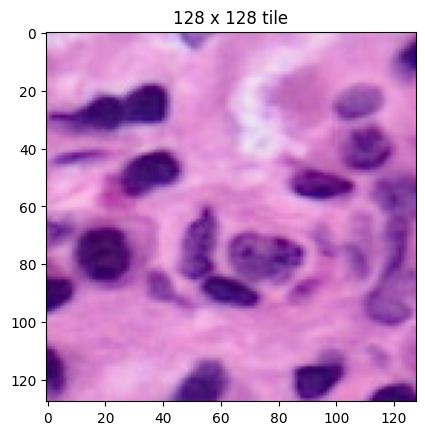

In [89]:
fov_size = 128

x_start, y_start = 2000+fov_size, 15000+fov_size

transform = Compose([
    ToTensor(), 
    Resize((224, 224)) # → Resize for ViT input
])

plt.imshow(image_data[x_start:x_start+fov_size,y_start:y_start+fov_size,:])
plt.title(f"{fov_size} x {fov_size} tile")
plt.show()

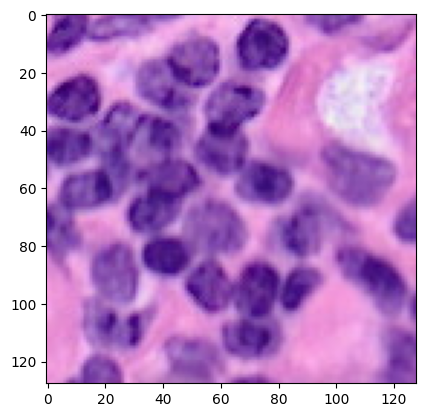

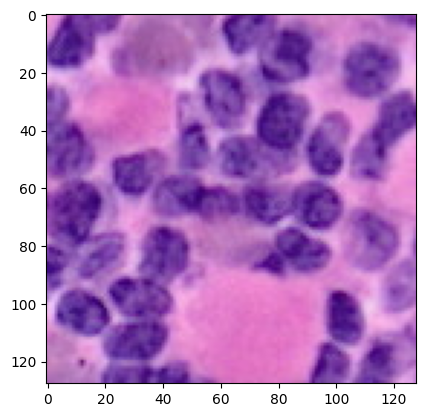

In [90]:
# Morphology similar, cell embedding similar: 2000, 1000
# Morphology NOT similar, cell embedding similar: 2500,3000

x_start, y_start = 20000, 10000
plt.imshow(image_data[x_start:x_start+fov_size,y_start:y_start+fov_size,:])
plt.show()

plt.imshow(image_data[x_start+fov_size:x_start+2*fov_size,y_start:y_start+fov_size,:])
plt.show()

In [ ]:
fov_image_A = image_data[x_start:x_start+fov_size, y_start:y_start+fov_size, :]
fov_image_B = image_data[x_start+fov_size:x_start+2*fov_size,y_start:y_start+fov_size,:]

x_A = transform(fov_image_A).unsqueeze(0)
x_B = transform(fov_image_B).unsqueeze(0)
with torch.no_grad():
    image_embedding_A = image_encoder(x_A)
    image_embedding_B = image_encoder(x_B)

F.cosine_similarity(image_embedding_A, image_embedding_B)

In [ ]:
points = x1.obsm['spatial']

mask = (
    (x_start <= points[:,0]) & (points[:,0] < x_start + fov_size) &  # x_pixel
    (y_start <= points[:,1]) & (points[:,1] < y_start + fov_size)    # y_pixel
)

FOV_A = x1.obsm["novae_latent"][mask]

mask = (
    (x_start + fov_size <= points[:,0]) & (points[:,0] < x_start + 2*fov_size) &  # x_pixel
    (y_start <= points[:,1]) & (points[:,1] < y_start + fov_size)    # y_pixel
)

FOV_B = x1.obsm["novae_latent"][mask]

# 합치기
all_cells = np.concatenate([FOV_A, FOV_B], axis=0)

# t-SNE 적용
tsne = TSNE(n_components=2, perplexity=3, random_state=42)
all_embedded = tsne.fit_transform(all_cells)

# 분리
A_emb = all_embedded[:len(FOV_A)]
B_emb = all_embedded[len(FOV_A):]

# 시각화
plt.figure(figsize=(6, 6))
plt.scatter(A_emb[:, 0], A_emb[:, 1], label='FOV A', alpha=0.7)
plt.scatter(B_emb[:, 0], B_emb[:, 1], label='FOV B', alpha=0.7)
plt.legend()
plt.title("NOVAE cell Embeddings from FOV A and B (t-SNE)")
plt.show()

In [ ]:
FOV_A.shape

In [ ]:
FOV_B.shape

In [ ]:
a = np.ones(FOV_A.shape[0]) / FOV_A.shape[0]
b = np.ones(FOV_B.shape[0]) / FOV_B.shape[0]

M = ot.dist(FOV_A, FOV_B, metric='euclidean')

# Compute Wasserstein distance
print(ot.emd2(a, b, M))

# Compute cosine similarity
print(F.cosine_similarity(torch.tensor(FOV_A.mean(axis=0)).unsqueeze(0), torch.tensor(FOV_B.mean(axis=0)).unsqueeze(0)))

In [ ]:
points = x1.obsm['spatial']

mask = (
    (x_start <= points[:,0]) & (points[:,0] < x_start + fov_size) &  # x_pixel
    (y_start <= points[:,1]) & (points[:,1] < y_start + fov_size)    # y_pixel
)

spatial_embedding = torch.Tensor(x1.obsm["novae_latent"][mask]).mean(axis=0).unsqueeze(0)

x2 = transform(image_data[x_start:x_start+fov_size,y_start:y_start+fov_size,:]).unsqueeze(0)

# image embedding
image_embedding = image_encoder(x2)

# Multiple FOV embeddings --> manifold

In [ ]:
slide_H, slide_W, _ = image_data.shape
fov_size = 256
stride = 256  

fov_coords = []
for x in range(0, slide_H - fov_size + 1, stride):
    for y in range(0, slide_W - fov_size + 1, stride):
        fov_coords.append((x, y))


spatial_embeddings = []
image_embeddings = []

for x_start, y_start in tqdm(fov_coords):
    # 1. spatial embedding (cells inside this FOV)
    mask = (
        (x_start <= points[:, 0]) & (points[:, 0] < x_start + fov_size) &
        (y_start <= points[:, 1]) & (points[:, 1] < y_start + fov_size)
    )
    if mask.sum() == 0:
        continue  # skip empty regions
    
    spatial_embedding = torch.Tensor(x1.obsm["novae_latent"][mask]).mean(dim=0).unsqueeze(0)
    spatial_embeddings.append(spatial_embedding)

    # 2. image embedding
    fov_image = image_data[x_start:x_start+fov_size, y_start:y_start+fov_size, :]
    x2 = transform(fov_image).unsqueeze(0)
    with torch.no_grad():
        image_embedding = image_encoder(x2)
    image_embeddings.append(image_embedding)

In [ ]:
stacked_spatial_embeddings = torch.stack(spatial_embeddings).squeeze(1)

In [ ]:
stacked_image_embeddings = torch.stack(image_embeddings).squeeze(1)

In [ ]:
stacked_image_embeddings.shape

In [ ]:
# with open(f"./spatial_embeddings_{tissue_type}.pkl", "wb") as f:
#     pickle.dump(stacked_spatial_embeddings, f)

# with open(f"./image_embeddings_{tissue_type}.pkl", "wb") as f:
#     pickle.dump(stacked_image_embeddings, f)

In [ ]:
with open(f"./spatial_embeddings_{tissue_type}.pkl", "rb") as f:
    stacked_spatial_embeddings = pickle.load(f)

with open(f"./image_embeddings_{tissue_type}.pkl", "rb") as f:
    stacked_image_embeddings = pickle.load(f)

In [ ]:
stacked_spatial_embeddings.shape

In [ ]:
stacked_image_embeddings.shape

In [ ]:
image_cosine_sim_null_dist = get_null_distribution(stacked_image_embeddings)
spatial_cosine_sim_null_dist = get_null_distribution(stacked_spatial_embeddings)

In [ ]:
image_cosine_sim_null_dist.median()

spatial_cosine_sim_null_dist.median()

target = F.cosine_similarity(image_embedding_A, image_embedding_B)
print(sum(image_cosine_sim_null_dist >= target) / len(image_cosine_sim_null_dist))

target = F.cosine_similarity(torch.tensor(FOV_A.mean(axis=0)).unsqueeze(0), torch.tensor(FOV_B.mean(axis=0)).unsqueeze(0))
print(sum(spatial_cosine_sim_null_dist >= target) / len(spatial_cosine_sim_null_dist))

# Plot

In [ ]:
A, B = stacked_spatial_embeddings.detach().numpy(), stacked_image_embeddings.detach().numpy()

scaler = StandardScaler()
A = scaler.fit_transform(A)
B = scaler.fit_transform(B)

# Step 1: 먼저 A, B 각각을 낮은 차원 (예: 5)으로 줄임
pca_A = PCA(n_components=5).fit_transform(A)
pca_B = PCA(n_components=5).fit_transform(B)

# Step 2: A, B를 세로로 붙여서 같이 PCA (같은 feature 수니까 가능)
AB = np.concatenate([pca_A, pca_B], axis=0)  # shape = (200, 50)

# Step 3: 같은 공간에 다시 PCA
joint = np.concatenate([pca_A, pca_B], axis=0)
joint_pca = PCA(n_components=2).fit_transform(joint)

pca_A_2d = joint_pca[:len(pca_A)]
pca_B_2d = joint_pca[len(pca_A):]

# 시각화
plt.figure(figsize=(8, 8))
plt.scatter(pca_A[:, 0], pca_A[:, 1], label='Spatial embedding', c='blue', alpha=0.2)
plt.title("Spatial embedding")
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()

plt.figure(figsize=(8, 8))
plt.scatter(pca_B[:, 0], pca_B[:, 1], label='Image embedding', c='orange', alpha=0.2)
plt.title("Image embedding")
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()

plt.figure(figsize=(8, 8))

plt.scatter(pca_A_2d[:, 0], pca_A_2d[:, 1], label='Spatial embedding', c='blue', alpha=0.2)
plt.scatter(pca_B_2d[:, 0], pca_B_2d[:, 1], label='Image embedding', c='orange', alpha=0.2)

plt.scatter(pca_A_2d[100, 0], pca_A_2d[100, 1], c='red', marker='o', s=100)
plt.scatter(pca_B_2d[100, 0], pca_B_2d[100, 1], c='red', marker='o', s=100)

plt.legend()
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()